[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/andreasmang/stan/blob/main/recitation/rec07/testing_demo.ipynb)

# Recitation 7 demo: size, power, and the delta method

We toss a coin $n$ times, count the heads $S\sim\text{Binomial}(n,p)$, and test

$$H_0: p\le \tfrac12 \qquad\text{against}\qquad H_1: p>\tfrac12$$

by rejecting $H_0$ when $S\ge c$. The **power function** $\beta(p)=\mathbb{P}_p(S\ge c)$ is the probability
that the test rejects when $p$ is the true parameter. On $p\le 1/2$ it is the probability of a type I
error; on $p>1/2$, one minus it is the probability of a type II error.

Run everything with **Runtime > Run all** (a few seconds), then change the numbers marked `# <-` and run again.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import comb, erf, sqrt

rng = np.random.default_rng(0)

def power(c, p, n=10):
    """Exact P_p(S >= c) for S ~ Binomial(n, p)."""
    return sum(comb(n, k) * p**k * (1 - p)**(n - k) for k in range(c, n + 1))

ps = np.linspace(0, 1, 201)
print("ready")

ready


## 1. The power function for $n=10$

Three choices of the critical value $c$. The dashed line marks $\alpha=0.05$; the dotted line marks
the boundary $p=1/2$ between $H_0$ (left) and $H_1$ (right).

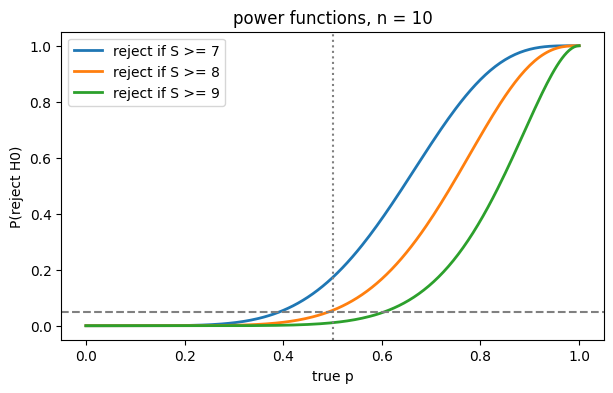

c = 7:  size = beta(1/2) = 0.172   power at p = 0.7: 0.650
c = 8:  size = beta(1/2) = 0.055   power at p = 0.7: 0.383
c = 9:  size = beta(1/2) = 0.011   power at p = 0.7: 0.149


In [2]:
n = 10
cs = [7, 8, 9]                                   # <- try other critical values

plt.figure(figsize=(7, 4))
for c in cs:
    plt.plot(ps, [power(c, p, n) for p in ps], linewidth=2, label=f"reject if S >= {c}")
plt.axhline(0.05, color="0.5", linestyle="--")
plt.axvline(0.5, color="0.5", linestyle=":")
plt.xlabel("true p"); plt.ylabel("P(reject H0)"); plt.title(f"power functions, n = {n}")
plt.legend(); plt.show()

for c in cs:
    print(f"c = {c}:  size = beta(1/2) = {power(c, 0.5, n):.3f}   power at p = 0.7: {power(c, 0.7, n):.3f}")

Each curve increases in $p$, so its highest point on $p\le1/2$ is at $p=1/2$: that height is the
**size**. Moving $c$ up lowers the whole curve: fewer type I errors, more type II errors.

## 2. The same numbers by simulation

The power function is a probability over repeated experiments. Here we repeat the experiment
20000 times and count how often the test rejects.

In [3]:
c, reps = 8, 20000                               # <- change c or the true p below
for p in [0.5, 0.7]:
    S = rng.binomial(n, p, size=reps)            # 20000 experiments of 10 tosses each
    print(f"p = {p}:  rejected in {np.mean(S >= c):.3f} of the experiments   (exact: {power(c, p, n):.3f})")

p = 0.5:  rejected in 0.055 of the experiments   (exact: 0.055)
p = 0.7:  rejected in 0.378 of the experiments   (exact: 0.383)


## 3. More tosses, same level

For each $n$ we choose the smallest $c$ with $\mathbb{P}_{1/2}(S\ge c)\le 0.05$, so every test has level 0.05.
Then we compare the power functions.

n =  10:  c =   9   size = 0.011   power at p = 0.7: 0.1493
n =  40:  c =  26   size = 0.040   power at p = 0.7: 0.8074
n = 160:  c =  91   size = 0.048   power at p = 0.7: 0.9998


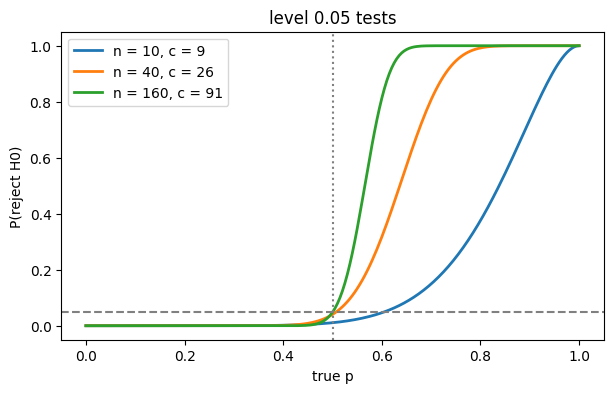

In [4]:
alpha = 0.05
plt.figure(figsize=(7, 4))
for n in [10, 40, 160]:                          # <- try other sample sizes
    c = next(c for c in range(n + 1) if power(c, 0.5, n) <= alpha)
    plt.plot(ps, [power(c, p, n) for p in ps], linewidth=2, label=f"n = {n}, c = {c}")
    print(f"n = {n:3d}:  c = {c:3d}   size = {power(c, 0.5, n):.3f}   power at p = 0.7: {power(c, 0.7, n):.4f}")
plt.axhline(alpha, color="0.5", linestyle="--")
plt.axvline(0.5, color="0.5", linestyle=":")
plt.xlabel("true p"); plt.ylabel("P(reject H0)"); plt.title("level 0.05 tests")
plt.legend(); plt.show()

The curves get steeper around $p=1/2$, toward the ideal test that rejects exactly when $H_1$ is true.
The size stays below 0.05 because $c$ is chosen again for each $n$. With $n$ fixed, $c$ only trades one error
for the other; more data is the only way to reduce both.

## 4. Does the delta method work? (Problem 2)

For $X_1,\dots,X_n\sim\text{Exponential}(\lambda)$, the MLE of $\psi=\mathbb{P}(X>1)=e^{-\lambda}$ is
$\widehat\psi=e^{-1/\overline{X}_n}$, and the delta method gives
$\operatorname{se}(\widehat\psi)\approx e^{-\lambda}\lambda/\sqrt n$. We simulate 100000 samples for each $n$ and compare
with the real spread of $\widehat\psi$, and check how often the interval $\widehat\psi\pm1.96\,\widehat{\operatorname{se}}$ covers $\psi$.

In [5]:
lam = 1.25                                       # <- the true rate
psi = np.exp(-lam)
for n in [5, 10, 20, 50, 200]:
    x = rng.exponential(1 / lam, size=(100000, n))   # numpy uses the scale 1/lambda
    lam_hat = 1 / x.mean(axis=1)
    psi_hat = np.exp(-lam_hat)
    se_delta = psi * lam / np.sqrt(n)                # delta method, at the true lambda
    se_hat = psi_hat * lam_hat / np.sqrt(n)          # estimated, as in the worksheet
    cover = np.mean(np.abs(psi_hat - psi) <= 1.96 * se_hat)
    print(f"n = {n:3d}:  real sd = {psi_hat.std():.4f}   delta method = {se_delta:.4f}   "
          f"ratio = {psi_hat.std() / se_delta:.2f}   95% interval covers psi: {cover:.3f}")

n =   5:  real sd = 0.1417   delta method = 0.1602   ratio = 0.88   95% interval covers psi: 0.858
n =  10:  real sd = 0.1062   delta method = 0.1133   ratio = 0.94   95% interval covers psi: 0.902
n =  20:  real sd = 0.0777   delta method = 0.0801   ratio = 0.97   95% interval covers psi: 0.923
n =  50:  real sd = 0.0500   delta method = 0.0506   ratio = 0.99   95% interval covers psi: 0.940


n = 200:  real sd = 0.0253   delta method = 0.0253   ratio = 1.00   95% interval covers psi: 0.947


For $n=50$ the delta method is within about 1% of the real spread, and the interval covers $\psi$ about
94% of the time. For $n=5$ it is off by more than 10% and the "95%" interval covers only about 86% of the time:
the delta method is a large-$n$ approximation.

## 5. Looking ahead: many tests

A level 0.05 test rejects a true $H_0$ at most 5% of the time. What if we run 20 independent tests, and
**every** null hypothesis is true? Here each test is the Gaussian test from the lecture,
reject if $\overline{X}_n>1.645\,\sigma/\sqrt n$, on data with $\mu=0$.

In [6]:
tests, reps, n = 20, 10000, 25                  # <- try 1, 5, 100 tests
x = rng.standard_normal(size=(reps, tests, n))    # mu = 0, sigma = 1: every H0 is true
reject = x.mean(axis=2) > 1.645 / np.sqrt(n)
print(f"each test alone rejects in {reject.mean():.3f} of the experiments")
print(f"at least one of the {tests} tests rejects in {reject.any(axis=1).mean():.3f} of the experiments"
      f"   (exact: 1 - 0.95^{tests} = {1 - 0.95**tests:.3f})")

each test alone rejects in 0.049 of the experiments
at least one of the 20 tests rejects in 0.639 of the experiments   (exact: 1 - 0.95^20 = 0.642)


Each test keeps its promise, yet with 20 tests at least one "discovery" is more likely than not.
Keep this in mind whenever you read that one of many comparisons was significant.

---

This notebook is part of STAN, the code repository for MATH 166 at Tufts University:
<https://github.com/andreasmang/stan>.